In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os

train_path = None
test_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    if "train.csv" in files:
        train_path = os.path.join(root, "train.csv")

    if "test.csv" in files:
        test_path = os.path.join(root, "test.csv")

print("Training file:", train_path)
print("Testing file:", test_path)

if train_path is None or test_path is None:
    print("ERROR: Dataset not found!")
    print("Kaggle Notebook ke Input section mein dataset add karo.")
else:
    print("Dataset files found successfully!")

Training file: /kaggle/input/competitions/digit-recognizer/train.csv
Testing file: /kaggle/input/competitions/digit-recognizer/test.csv
Dataset files found successfully!


In [3]:
if train_path is None or test_path is None:
    raise FileNotFoundError(
        "Dataset nahi mila. Pehle Cell 2 ka output check karo."
    )

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

display(train.head())

Training Dataset Shape: (42000, 785)
Testing Dataset Shape: (28000, 784)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
print("Dataset Information:")
train.info()

print("\nMissing Values:", train.isnull().sum().sum())

print("\nDuplicate Rows:", train.duplicated().sum())

print("\nDigit Distribution:")
print(train["label"].value_counts().sort_index())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB

Missing Values: 0

Duplicate Rows: 0

Digit Distribution:
label
0    4132
1    4684
2    4177
3    4351
4    4072
5    3795
6    4137
7    4401
8    4063
9    4188
Name: count, dtype: int64


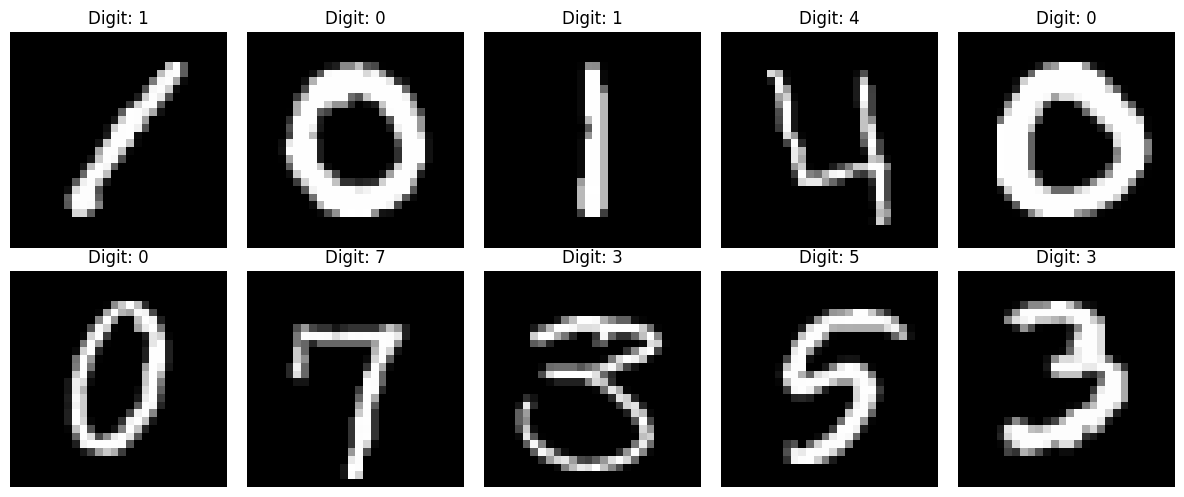

In [5]:
X = train.drop("label", axis=1)
y = train["label"]

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = X.iloc[i].to_numpy().reshape(28, 28)

    plt.imshow(image, cmap="gray")
    plt.title(f"Digit: {y.iloc[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_valid.shape[0])

Training samples: 33600
Validation samples: 8400


In [7]:
model = ExtraTreesClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

print("Model created successfully!")

Model created successfully!


In [8]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [9]:
y_pred = model.predict(X_valid)

accuracy = accuracy_score(y_valid, y_pred)

print(f"Validation Accuracy: {accuracy * 100:.2f}%")

Validation Accuracy: 96.98%


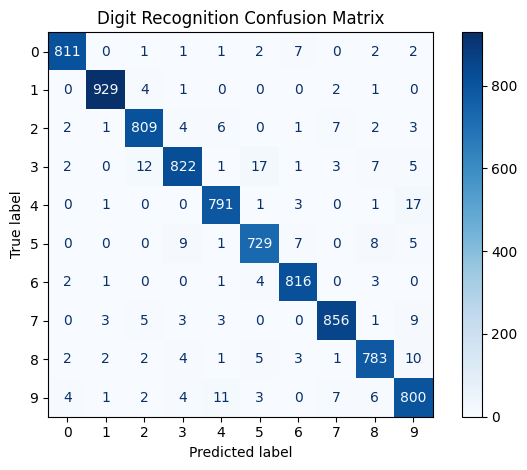

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    y_pred,
    cmap="Blues"
)

plt.title("Digit Recognition Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
model.fit(X, y)

print("Final model trained on complete dataset!")

Final model trained on complete dataset!


In [12]:
predictions = model.predict(test)

print("Predictions generated:", len(predictions))
print("First 10 predictions:", predictions[:10])

submission = pd.DataFrame({
    "ImageId": range(1, len(predictions) + 1),
    "Label": predictions.astype(int)
})

submission.to_csv("submission.csv", index=False)

print("Submission file created!")
display(submission.head())

print("Submission shape:", submission.shape)

Predictions generated: 28000
First 10 predictions: [2 0 9 9 3 7 0 3 0 3]
Submission file created!


,ImageId,Label
0,1,2
1,2,0
2,3,9
3,4,9
4,5,3


Submission shape: (28000, 2)


In [13]:
from IPython.display import FileLink, display

display(FileLink("submission.csv"))

/kaggle/working/submission.csv